In [1]:
%pip install -q --break-system-packages -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
import csv
import hashlib
import os
import re
import subprocess

os.environ["HF_HOME"] = "models/hf"  # must be set before mlx_lm is imported

import matplotlib.pyplot as plt
import pandas as pd
import requests
from tqdm import tqdm

ORCAS_URL = "https://msmarco.z22.web.core.windows.net/msmarcoranking/orcas.tsv.gz"
DOCS_URL = "https://msmarco.z22.web.core.windows.net/msmarcoranking/msmarco-docs.tsv.gz"
OUT_PATH = "data/data.parquet"
RAW = "data/raw"  # downloads, gitignored

N_SAMPLE = 300_000
SEED = 0


def seeded_hash(key):
    return int(hashlib.md5(f"{SEED}:{key}".encode()).hexdigest()[:15], 16)


BLUE = "#2a78d6"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#898781",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.labelcolor": "#52514e",
    "axes.titlelocation": "left", "axes.titlesize": 11,
})
os.makedirs("results", exist_ok=True)

In [3]:
# curl -C - resumes a broken download; files already complete are skipped.
def download(url, path):
    size = int(requests.head(url, timeout=30).headers["Content-Length"])
    if not os.path.exists(path) or os.path.getsize(path) < size:
        subprocess.run(["curl", "-fL", "-C", "-", "--retry", "5", "-o", path, url], check=True)


os.makedirs(RAW, exist_ok=True)
download(ORCAS_URL, f"{RAW}/orcas.tsv.gz")
download(DOCS_URL, f"{RAW}/msmarco-docs.tsv.gz")

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  314M  100  314M    0     0  8671k      0  0:00:37  0:00:37 --:--:-- 7326k
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 8054M  100 8054M    0     0  6135k      0  0:22:24  0:22:24 --:--:-- 9734k


In [4]:
orcas = pd.read_csv(f"{RAW}/orcas.tsv.gz", sep="\t", names=["qid", "query", "did", "url"],
                    dtype=str, quoting=csv.QUOTE_NONE, keep_default_na=False)
orcas = orcas.drop_duplicates(["qid", "did"])
orcas["query"] = orcas["query"].str.strip()
print(f"{len(orcas):,} clicks, {orcas['qid'].nunique():,} queries, {orcas['did'].nunique():,} pages")

18,823,332 clicks, 10,405,342 queries, 1,422,029 pages


In [5]:
# What the query filters would remove.
no_alnum = ~orcas["query"].str.contains(r"[^\W_]")
non_ascii = ~orcas["query"].map(str.isascii)
print(f"No letters or digits: {no_alnum.mean():.2%} of clicks, e.g. {orcas.loc[no_alnum, 'query'].head(5).tolist()}")
print(f"Non-ASCII:            {non_ascii.mean():.2%} of clicks, e.g. {orcas.loc[non_ascii, 'query'].sample(5, random_state=SEED).tolist()}")

No letters or digits: 0.00% of clicks, e.g. ['!', '!', '!', '!', '!']
Non-ASCII:            0.25% of clicks, e.g. ['kartoffelrÃ¶sti', 'huracÃ¡n wilma', 'cretaceousâpaleogene extinction event', 'apple å®ç½', 'yahoo mailÃ¹']


In [6]:
pairs = orcas[~no_alnum & ~non_ascii]
needed_dids = set(pairs["did"])
print(f"{len(pairs):,} clicks kept, {len(needed_dids):,} pages needed")

18,775,257 clicks kept, 1,421,710 pages needed


In [7]:
# Keep only the doc ID and title columns, so the ~22 GB of page bodies are never parsed.
if not os.path.exists(f"{RAW}/doc_titles.tsv"):
    !set -o pipefail; gunzip -c {RAW}/msmarco-docs.tsv.gz | cut -f1,3 > {RAW}/doc_titles.tmp && mv {RAW}/doc_titles.tmp {RAW}/doc_titles.tsv

docs = pd.read_csv(f"{RAW}/doc_titles.tsv", sep="\t", names=["did", "title"], dtype=str, quoting=csv.QUOTE_NONE,
                   keep_default_na=False, lineterminator="\n", encoding_errors="replace")
docs = docs[docs["did"].isin(needed_dids)]
titles = dict(zip(docs["did"], docs["title"].str.strip()))
del docs
print(f"titles for {len(titles):,} of {len(needed_dids):,} pages")

titles for 1,421,710 of 1,421,710 pages


over 10 words:  7.01% of pages
over 15 words:  1.61% of pages
over 20 words:  0.67% of pages
over 30 words:  0.24% of pages
over 50 words:  0.12% of pages


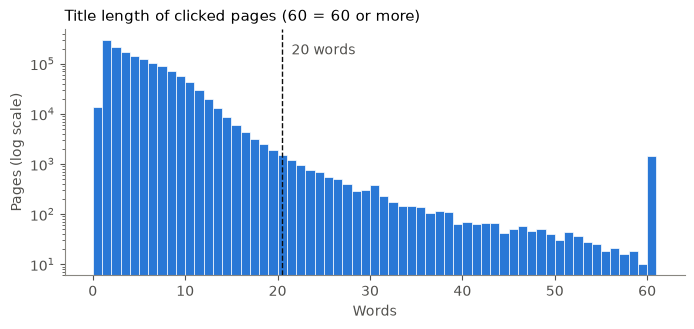


1-10 words (1,308,671 pages)
    Metabolism, Cellular
    Yahya Jammeh
    Coraline  (film)
    99+% Pure CBD Isolate Powder from Hemp

11-20 words (90,086 pages)
    Get Better Credit - How To Make My Credit Score Go Up Fast
    Analytical Thinking: Why You Need It and How to Get Better
    T.J. Holmes Joins ABC News as Co-Anchor of âAmerica This Morningâ and âWorld News Nowâ
    Hammers â All You Need to Know about the Different Types of Hammer and What They are Used For

21-30 words (6,064 pages)
    Checkout out as a new customerCreating an account has many benefits:See order and shipping statusTrack order historyCheck out fasterCreate an AccountCheckout ou
    Water education news: Questions and Answers about water pollution â water shortages â water contamination â What are some facts about water? â 100 water facts y
    Find a Person ONEcard Bear Tracks Maps Email & Apps eClass LibrariesSearchOffice of the RegistrarFees Financial Support Registration Examinations Records Convoc

In [8]:
# Title length per page, to choose the cutoff between real titles and scraped page text.
page_titles = pd.Series(titles)
title_words = page_titles.str.split().str.len()
for cutoff in [10, 15, 20, 30, 50]:
    print(f"over {cutoff:>2} words: {(title_words > cutoff).mean():6.2%} of pages")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(title_words.clip(upper=60), bins=range(0, 62), color=BLUE, edgecolor="white", linewidth=0.5)
ax.axvline(20.5, color="#0b0b0b", linestyle="--", linewidth=1)
ax.text(21.5, ax.get_ylim()[1] * 0.5, "20 words", color="#52514e")
ax.set_yscale("log")
ax.set(title="Title length of clicked pages (60 = 60 or more)", xlabel="Words", ylabel="Pages (log scale)")
plt.savefig("results/title_lengths.png", dpi=200, bbox_inches="tight")
plt.show()

bands = pd.cut(title_words, [0, 10, 20, 30, 10_000], labels=["1-10", "11-20", "21-30", "31+"])
for band, group in page_titles.groupby(bands, observed=True):
    print(f"\n{band} words ({len(group):,} pages)")
    for title in group.sample(min(4, len(group)), random_state=SEED):
        print("   ", title[:160])

In [9]:
MAX_TITLE_WORDS = 20  # from the chart and examples above

pairs = pairs.assign(title=pairs["did"].map(titles)).dropna(subset=["title"])
title_ok = pairs["title"].str.contains(r"[^\W_]") & (pairs["title"].str.split().str.len() <= MAX_TITLE_WORDS)
pairs = pairs[title_ok].copy()
pairs["url"] = (pairs["url"].str.replace(r"^\w+://", "", regex=True)
                            .str.replace(r"^www\.", "", regex=True)
                            .str.rstrip("/"))
print(f"{len(pairs):,} clicks after title filters")

# One answer per query, then one query per page, both chosen by seeded hash.
pairs["answer_hash"] = (pairs["qid"] + pairs["did"]).map(seeded_hash)
pairs["order"] = pairs["qid"].map(seeded_hash)
pairs = pairs.sort_values("answer_hash").drop_duplicates("qid")
pairs = pairs.sort_values("order").drop_duplicates("did")
print(f"{len(pairs):,} query-page pairs")

16,537,009 clicks after title filters
1,070,453 query-page pairs


In [10]:
clicked = orcas[orcas["qid"].isin(pairs["qid"])].groupby("qid")["did"].agg(list)
pairs["clicked_dids"] = pairs["qid"].map(clicked)

n_clicks = pairs["clicked_dids"].str.len()
print(f"clicked pages per query: mean {n_clicks.mean():.2f}, {(n_clicks > 1).mean():.1%} clicked more than one")

clicked pages per query: mean 2.02, 46.3% clicked more than one


In [11]:
data = (pairs.head(N_SAMPLE)
             .rename(columns={"did": "answer_did"})
             [["qid", "query", "answer_did", "title", "url", "clicked_dids"]]
             .reset_index(drop=True))

# Keep rewrites from an earlier run.
if os.path.exists(OUT_PATH):
    old = pd.read_parquet(OUT_PATH, columns=["qid", "train_question", "train_score", "test_question", "test_score"])
    data = data.merge(old, on="qid", how="left")
else:
    data["train_question"] = pd.Series(dtype="string")
    data["train_score"] = pd.Series(dtype="float")
    data["test_question"] = pd.Series(dtype="string")
    data["test_score"] = pd.Series(dtype="float")

del orcas, titles, page_titles
print(f"{len(data):,} rows, {data['train_question'].notna().sum():,} already rewritten")

300,000 rows, 0 already rewritten


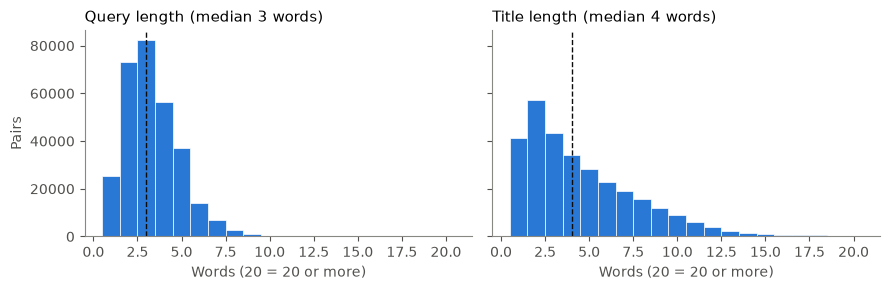

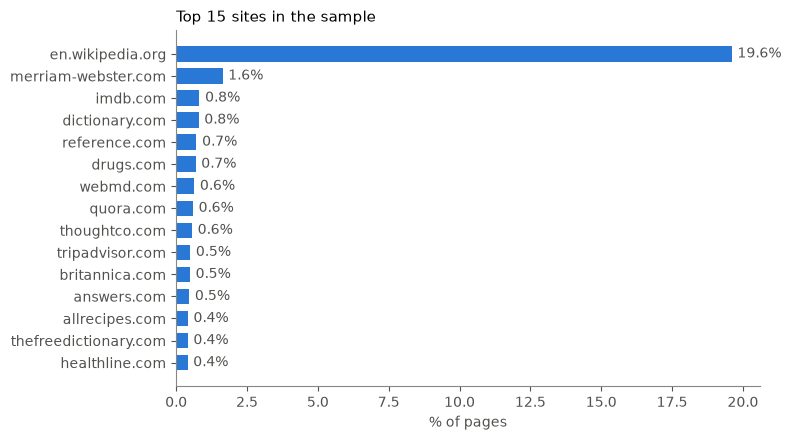

65,458 distinct sites


In [12]:
# Query and title lengths in the sample: short keyword searches are why the queries need rewriting.
fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
for ax, col in zip(axes, ["query", "title"]):
    words = data[col].str.split().str.len()
    ax.hist(words.clip(upper=20), bins=range(1, 22), align="left", color=BLUE, edgecolor="white", linewidth=0.5)
    ax.axvline(words.median(), color="#0b0b0b", linestyle="--", linewidth=1)
    ax.set(title=f"{col.capitalize()} length (median {words.median():.0f} words)", xlabel="Words (20 = 20 or more)")
axes[0].set_ylabel("Pairs")
plt.tight_layout()
plt.savefig("results/lengths.png", dpi=200, bbox_inches="tight")
plt.show()

# Which sites the pages come from.
sites = data["url"].str.split("/").str[0].value_counts()
top = sites.head(15) / len(data) * 100
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top.index, top.values, color=BLUE, height=0.7)
ax.invert_yaxis()
for i, share in enumerate(top.values):
    ax.text(share + 0.2, i, f"{share:.1f}%", va="center", color="#52514e")
ax.set(title="Top 15 sites in the sample", xlabel="% of pages")
plt.tight_layout()
plt.savefig("results/top_sites.png", dpi=200, bbox_inches="tight")
plt.show()
print(f"{len(sites):,} distinct sites")

In [13]:
def save(df):
    assert df["qid"].is_unique
    assert df["answer_did"].is_unique
    assert all(did in clicks for did, clicks in zip(df["answer_did"], df["clicked_dids"]))
    assert (df["title"].str.strip() != "").all() and (df["url"].str.strip() != "").all()
    os.makedirs("data", exist_ok=True)
    df.to_parquet(OUT_PATH, compression="zstd", index=False)
    print(f"saved {len(df):,} rows, {os.path.getsize(OUT_PATH) / 1e6:.1f} MB")


save(data)

saved 300,000 rows, 21.8 MB


In [14]:
import mlx.core as mx
from mlx_lm import batch_generate, load
from mlx_lm.models.cache import make_prompt_cache

QWEN = "mlx-community/Qwen3-30B-A3B-Instruct-2507-4bit"
SAVE_EVERY = 2_000
BATCH_SIZE = 64

model, tokenizer = load(QWEN)

/Users/adiram/.local/share/uv/python/cpython-3.11.15-macos-aarch64-none/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 14 files: 100%|██████████| 14/14 [00:00<00:00, 3043.45it/s]


In [15]:
SYSTEM = """You rewrite search-engine queries into questions a person would ask an AI assistant that searches their own browsing history.

You will get the keyword query someone typed and the title and URL of the page they clicked. Imagine that same person days later, trying to find that page again by asking the assistant in plain, everyday words.

Rules:
- Write one complete, grammatical question or request, 6 to 20 words, in casual language. Ask only one thing.
- Refer to the page as something they already saw ("that article", "the recipe I found", "the video I watched"), and vary how you do it.
- Vary how the question starts, as the examples do. Most questions should not start with "Where".
- Keep the main name a person would remember, such as the show, product, person or place, so the page can still be found. Describe the rest loosely, the way people do when half-remembering.
- Never copy three or more words in a row from the page title.
- Name the website only when a person would naturally remember it, like a video on YouTube or a listing on Zillow. Most questions should not name the site.
- When the title is vague, use the URL to work out what the page is about. Names in the URL, like a Wikipedia article name, are fine to use, but never copy ID numbers, codes or file names.
- Use only information in the query, title or URL. Do not invent details like dates, times, prices or reasons.
- Output only the question, with no quotes or explanation."""

EXAMPLES = [
    ("stranger things netflix", "Stranger Things | Netflix Official Site", "netflix.com/title/80057281",
     "Pull up the Stranger Things page I had open on Netflix."),
    ("best budget laptops", "The 6 Best Budget Laptops - RTINGS.com", "rtings.com/laptop/reviews/best/budget",
     "Which cheap laptops was I looking at?"),
    ("john amos", "Biography", "imdb.com/name/nm0025309/bio",
     "Can you get me that John Amos bio again?"),
    ("chicken thigh oven temp", "How Long to Bake Chicken Thighs at 400°F", "allrecipes.com/article/how-long-to-bake-chicken-thighs",
     "What oven temperature did that chicken thigh recipe say to use?"),
    ("how to tie a tie youtube", "How to Tie a Tie (Windsor Knot) - YouTube", "youtube.com/watch?v=xAg7z6u4NE8",
     "Find that YouTube video I watched on tying a tie."),
    ("zillow austin rentals", "Austin TX Apartments for Rent | Zillow", "zillow.com/austin-tx/rentals",
     "Go back to those Austin apartment listings I saw on Zillow."),
    ("irs w4 form", "About Form W-4, Employee's Withholding Certificate | Internal Revenue Service", "irs.gov/forms-pubs/about-form-w-4",
     "What happened to that W-4 tax form I was filling out?"),
    ("list comprehension python", "Python - List Comprehension - GeeksforGeeks", "geeksforgeeks.org/python-list-comprehension",
     "I need that Python tutorial on list comprehensions again."),
    ("symptoms of low iron", "Iron Deficiency Anemia: Symptoms, Causes & Treatment", "my.clevelandclinic.org/health/diseases/22908-iron-deficiency-anemia",
     "Bring up the article I read about signs of low iron."),
]
# Three sets of three; each mixes a question, a request, and another form.
EXAMPLE_SETS = [EXAMPLES[0:3], EXAMPLES[3:6], EXAMPLES[6:9]]


def build_prompt(examples, query, title, url):
    messages = [{"role": "system", "content": SYSTEM}]
    for q, t, u, answer in examples:
        messages.append({"role": "user", "content": f"Query: {q}\nPage title: {t}\nURL: {u}"})
        messages.append({"role": "assistant", "content": answer})
    messages.append({"role": "user", "content": f"Query: {query}\nPage title: {title}\nURL: {url}"})
    return tokenizer.apply_chat_template(messages, add_generation_prompt=True, tokenize=False)

In [16]:
# Everything before the final user turn is the same for every row in a set, so it is run through the model once per set.
prefixes = []
for examples in EXAMPLE_SETS:
    prompt = build_prompt(examples, "", "", "")
    prefix = prompt[:prompt.rindex("<|im_start|>user")]
    cache = make_prompt_cache(model)
    model(mx.array(tokenizer.encode(prefix, add_special_tokens=False))[None], cache=cache)
    mx.eval([c.state for c in cache])
    prefixes.append((prefix, cache))


def rewrite(rows, set_id):
    prefix, cache = prefixes[set_id]
    prompts = [tokenizer.encode(build_prompt(EXAMPLE_SETS[set_id], r.query, r.title, r.url)[len(prefix):], add_special_tokens=False)
               for r in rows.itertuples()]
    out = batch_generate(model, tokenizer, prompts, prompt_caches=[cache] * len(prompts), max_tokens=40,
                         return_logprobs=True, completion_batch_size=BATCH_SIZE, prefill_batch_size=BATCH_SIZE)
    scores = [sum(lp) / len(lp) if lp else float("nan") for lp in out.logprobs]
    return [t.strip() for t in out.texts], scores

In [17]:
set_ids = pd.Series([seeded_hash(q) % len(EXAMPLE_SETS) for q in data["qid"]], index=data.index)
todo = data.index[data["train_question"].isna()]

for start in tqdm(range(0, len(todo), SAVE_EVERY)):
    chunk = data.loc[todo[start:start + SAVE_EVERY]]
    for set_id, rows in chunk.groupby(set_ids):
        questions, scores = rewrite(rows, set_id)
        data.loc[rows.index, "train_question"] = questions
        data.loc[rows.index, "train_score"] = scores
    save(data)

  1%|          | 1/150 [03:51<9:34:58, 231.53s/it]

saved 300,000 rows, 21.9 MB


  1%|▏         | 2/150 [07:49<9:40:19, 235.26s/it]

saved 300,000 rows, 21.9 MB


  2%|▏         | 3/150 [11:59<9:53:03, 242.06s/it]

saved 300,000 rows, 22.0 MB


... (290 outputs left out)

 99%|█████████▉| 149/150 [8:41:20<03:22, 202.58s/it]

saved 300,000 rows, 28.9 MB


100%|██████████| 150/150 [8:44:42<00:00, 209.88s/it]

saved 300,000 rows, 29.0 MB


300,000 rewrites
within 6-20 words:          99.9%
copy 4+ title words:        4.9%
contain CJK characters:     0.00%
duplicate questions:        1,170


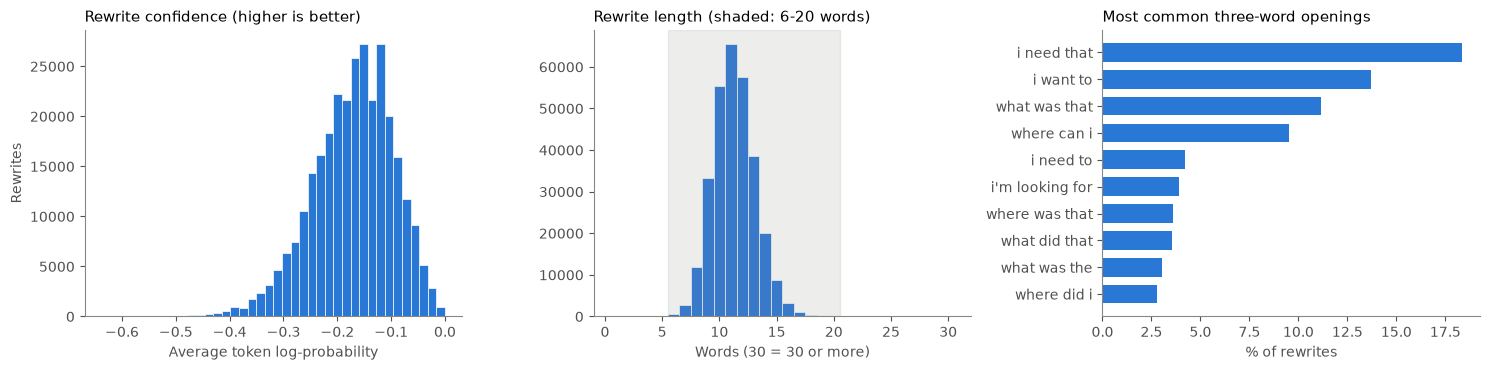

,query,title,train_question,train_score
76039,citigrou,Citigroup,Where was that Citigroup page I read about?,-0.637500
95428,horizontal sliding window air conditioner,The Best Air Conditioner,I need that page about the best window AC unit...,-0.625000
79332,girlfriends day,Girl Friends Day,What’s that holiday I found for girlfriends?,-0.625000
173207,www.agoogleaday.com,We ask a question,Where was that fun quiz I played about googlin...,-0.614583
282834,eagle county classifieds,Eagle County Colorado -Weather â the weeks ahe...,"That Eagle County weather page I saw, where wa...",-0.614583
184241,first ronald mcdonald,Ronald McDonald,Where was that first Ronald McDonald video I saw?,-0.600000
204048,the mechanic 2,Mechanic: Resurrection ( 2016),Where's that video I watched with the mechanic...,-0.598214
217739,aniversary,anniversary,I was looking for that word definition on anni...,-0.587500
38534,abra,Abra,What’s that Pokémon I saw with the psychic mov...,-0.583333
91719,never ending pool,Swim at HomeAll the benefits of traditional sw...,Where did I see that small pool that's like a ...,-0.571429


In [18]:
# Rewrite quality: confidence, length against the prompt's 6-20 word rule, title copying, and phrasing variety.
def copies_title(question, title):
    # True if the question repeats four or more consecutive title words.
    t = re.findall(r"\w+", title.lower())
    q = " " + " ".join(re.findall(r"\w+", question.lower())) + " "
    return any(" " + " ".join(t[i:i + 4]) + " " in q for i in range(len(t) - 3))


r = data[data["train_question"].notna()].copy()
r["words"] = r["train_question"].str.split().str.len()
r["opening"] = r["train_question"].str.lower().str.split().str[:3].str.join(" ")
print(f"{len(r):,} rewrites")
print(f"within 6-20 words:          {r['words'].between(6, 20).mean():.1%}")
print(f"copy 4+ title words:        {pd.Series([copies_title(q, t) for q, t in zip(r['train_question'], r['title'])]).mean():.1%}")
has_cjk = r["train_question"].str.contains("[\u3040-\u30ff\u4e00-\u9fff]")
print(f"contain CJK characters:     {has_cjk.mean():.2%}")
print(f"duplicate questions:        {r['train_question'].duplicated().sum():,}")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(r["train_score"], bins=40, color=BLUE, edgecolor="white", linewidth=0.5)
axes[0].set(title="Rewrite confidence (higher is better)", xlabel="Average token log-probability", ylabel="Rewrites")
axes[1].hist(r["words"].clip(upper=30), bins=range(1, 32), align="left", color=BLUE, edgecolor="white", linewidth=0.5)
axes[1].axvspan(5.5, 20.5, color="#898781", alpha=0.15)
axes[1].set(title="Rewrite length (shaded: 6-20 words)", xlabel="Words (30 = 30 or more)")
top = r["opening"].value_counts().head(10) / len(r) * 100
axes[2].barh(top.index, top.values, color=BLUE, height=0.7)
axes[2].invert_yaxis()
axes[2].set(title="Most common three-word openings", xlabel="% of rewrites")
plt.tight_layout()
plt.savefig("results/rewrite_quality.png", dpi=200, bbox_inches="tight")
plt.show()

r.sort_values("train_score")[["query", "title", "train_question", "train_score"]].head(10)